# Import pakietów

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib as mp
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()
import sklearn

## Weryfikacja wersji pakietów

In [2]:
print('Python:       ' + sys.version.split()[0])
print('NumPy:        ' + np.__version__)
print('pandas:       ' + pd.__version__)
print('Matplotlib:   ' + mp.__version__)
print('Seaborn:      ' + sns.__version__)
print('Scikit-learn: ' + sklearn.__version__)

Python:       3.13.16
NumPy:        2.1.3
pandas:       2.2.3
Matplotlib:   3.10.0
Seaborn:      0.13.2
Scikit-learn: 1.6.1


# Regresja liniowa

## Wczytanie danych

In [3]:
df = pd.read_csv('reglin_1.csv')
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       50 non-null     float64
 1   y       50 non-null     float64
dtypes: float64(2)
memory usage: 932.0 bytes


,x,y
0,3.745401,3.229269
1,9.507143,14.185654
2,7.319939,9.524231
3,5.986585,6.672066
4,1.560186,-3.358149


## Wykres punktowy

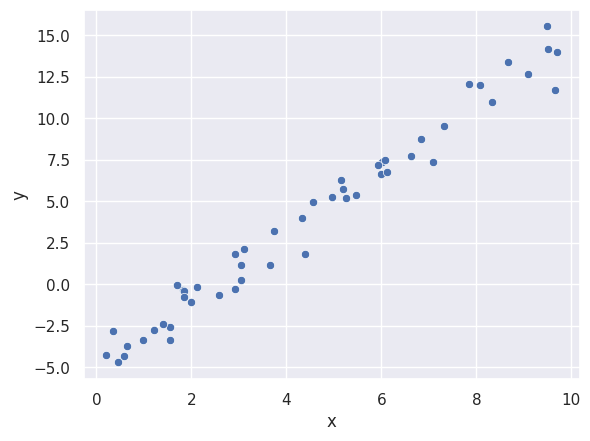

In [4]:
sns.scatterplot(df, x='x', y='y');

### Wyznaczanie parametrów modelu

In [5]:
xm = df['x'].mean()
ym = df['y'].mean()
a = ((df['x'] - xm)*(df['y'] - ym)).sum() / ((df['x'] - xm)**2).sum()
b = ym - a*xm
print('a = ', a)
print('b =', b)

a =  1.9776566003853109
b = -4.903310725531116


### Wyliczenie przewidywań i wizualizacja modelu

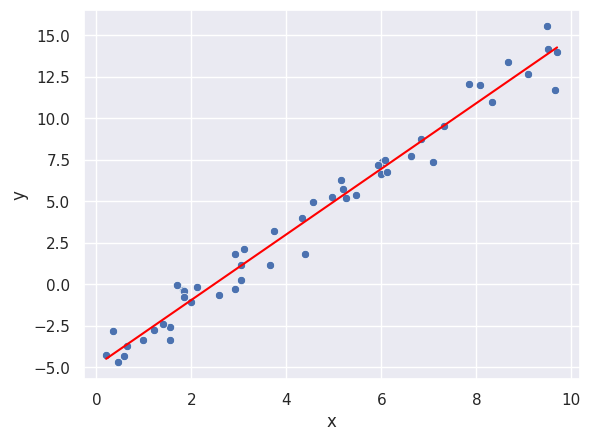

In [6]:
yp = a*df['x'] + b
sns.scatterplot(df, x='x', y='y')
sns.lineplot(df, x='x', y=yp, color='red');

### Metryki modelu

In [7]:
MAE = (df['y'] - yp).abs().mean()
RMSE = np.sqrt(((df['y'] - yp)**2).mean())
R2 = ((yp - ym)**2).sum() / ((df['y'] - ym)**2).sum()
print('MAE  =', MAE)
print('RMSE =', RMSE)
print('R2   =', R2)

MAE  = 0.7306407201834605
RMSE = 0.9072326844579001
R2   = 0.9749140085676866


## Dwie zmienne niezależne

In [8]:
df12 = pd.read_csv('reglin_12.csv')
df12.info()
df12.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      50 non-null     float64
 1   x2      50 non-null     float64
 2   y       50 non-null     float64
dtypes: float64(3)
memory usage: 1.3 KB


,x1,x2,y
0,3.745401,6.787092,-7.423853
1,9.507143,5.425930,7.019220
2,7.319939,6.576493,0.159716
3,5.986585,6.263791,-3.636347
4,1.560186,4.185300,-5.005185


### Import pakietu plotly

In [9]:
import plotly.express as px
import plotly.graph_objects as go

In [10]:
fig = go.Figure()
fig.add_scatter3d(x=df12['x1'], y=df12['x2'], z=df12['y'],
                  mode='markers', marker=dict(color='blue'))
fig.update_layout(scene = dict(xaxis=dict(title=dict(text='x1')),
                               yaxis=dict(title=dict(text='x2')),
                               zaxis=dict(title=dict(text='y'))))
fig.show()

### Wykorzystanie scikit-learn do regresji

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

In [12]:
lr = LinearRegression()
lr.fit(df[['x']], df['y'])
yp = lr.predict(df[['x']])
lr.score(df[['x']], df['y'])

0.9749140085676858

In [13]:
print('a =  ', lr.coef_[0])
print('b = ', lr.intercept_)

a =   1.9776566003853107
b =  -4.903310725531115


### Ocena modelu

In [14]:
MAE = mean_absolute_error(df['y'], yp)
RMSE = root_mean_squared_error(df['y'], yp)
R2 = r2_score(df['y'], yp)
print('MAE  =', MAE)
print('RMSE =', RMSE)
print('R2   =', R2)

MAE  = 0.7306407201834605
RMSE = 0.9072326844579003
R2   = 0.9749140085676858


### Dwie zmienne uczące

In [15]:
lr12 = LinearRegression()
lr12.fit(df12[['x1', 'x2']], df12['y'])
yp12 = lr12.predict(df12[['x1', 'x2']])
print('a =  ', lr12.coef_)
print('b = ', lr12.intercept_)
print('R2 =', lr12.score(df12[['x1', 'x2']], df12['y']))

a =   [ 1.87296192 -3.00045087]
b =  5.586753915354075
R2 = 0.988230503029934


### Ocena modelu

In [16]:
MAE = mean_absolute_error(df12['y'], yp12)
RMSE = root_mean_squared_error(df12['y'], yp12)
R2 = r2_score(df12['y'], yp12)
print('MAE  =', MAE)
print('RMSE =', RMSE)
print('R2   =', R2)

MAE  = 0.7070638224462258
RMSE = 0.8807987107359024
R2   = 0.988230503029934


### Wizualizacja modelu

In [17]:
x1_fit = np.linspace(0, 10, 100)
x2_fit = np.linspace(0, 7, 100)
X1, X2 = np.meshgrid(x1_fit, x2_fit)
Y = lr12.coef_[0]*X1 + lr12.coef_[1]*X2 + lr12.intercept_

In [18]:
fig = go.Figure(data=[go.Surface(x=X1, y=X2, z=Y,
                                 colorscale=[[0, 'red'], [1, 'red']],
                                 showscale=False,
                                 opacity=0.6)])
fig.add_scatter3d(x=df12['x1'], y=df12['x2'], z=df12['y'],
                  mode='markers', marker=dict(color='blue'))
fig.update_layout(scene = dict(xaxis=dict(title=dict(text='x1')),
                               yaxis=dict(title=dict(text='x2')),
                               zaxis=dict(title=dict(text='y'))))
fig.show()

# Regresja wielomianowa

In [19]:
df2 = pd.read_csv('reglin_2.csv')
df2.info()
df2.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       50 non-null     float64
 1   y       50 non-null     float64
dtypes: float64(2)
memory usage: 932.0 bytes


,x,y
0,3.745401,-0.329495
1,9.507143,18.185614
2,7.319939,10.322921
3,5.986585,4.293732
4,1.560186,-2.266792


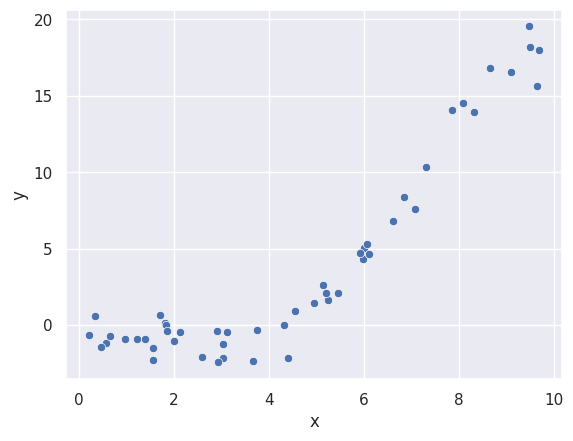

In [20]:
sns.scatterplot(df2, x='x', y='y');

In [21]:
lr2a = LinearRegression()
lr2a.fit(df2[['x']], df2['y'])
lr2a.score(df2[['x']], df2['y'])

0.8084065079290149

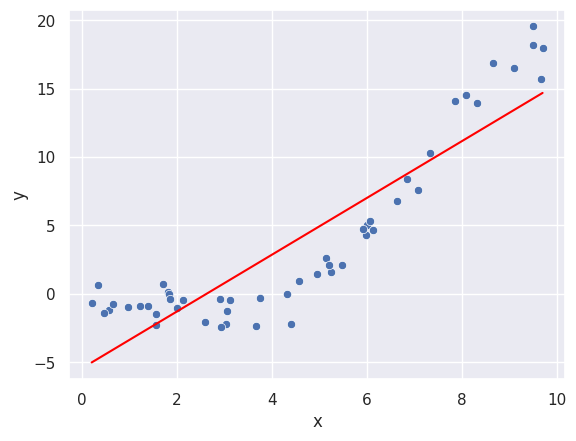

In [22]:
ypa = lr2a.coef_[0]*df2['x'] + lr2a.intercept_
sns.scatterplot(df2, x='x', y='y')
sns.lineplot(x=df2['x'], y=ypa, color='red');

## Generacja zmiennych (2 stopnia)

In [23]:
df2['x2'] = df2['x']**2
df2.info()
df2.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       50 non-null     float64
 1   y       50 non-null     float64
 2   x2      50 non-null     float64
dtypes: float64(3)
memory usage: 1.3 KB


,x,y,x2
0,3.745401,-0.329495,14.028030
1,9.507143,18.185614,90.385769
2,7.319939,10.322921,53.581513
3,5.986585,4.293732,35.839198
4,1.560186,-2.266792,2.434182


In [24]:
lr2b = LinearRegression()
lr2b.fit(df2[['x', 'x2']], df2['y'])
lr2b.score(df2[['x', 'x2']], df2['y'])

0.9626730764178592

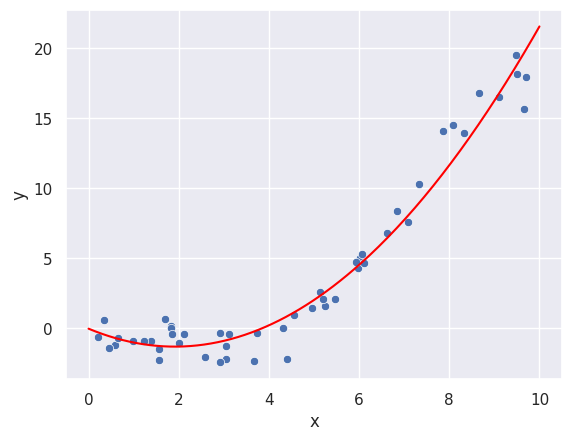

In [25]:
xfit = np.linspace(0, 10, 200)
yfit = lr2b.coef_[0]*xfit + lr2b.coef_[1]*xfit**2 + lr2b.intercept_
sns.scatterplot(df2, x='x', y='y')
sns.lineplot(x=xfit, y=yfit, color='red');

In [26]:
df3 = pd.read_csv('reglin_3.csv')
df3.info()
df3.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       50 non-null     float64
 1   y       50 non-null     float64
dtypes: float64(2)
memory usage: 932.0 bytes


,x,y
0,5.618102,3.921815
1,14.260715,19.737921
2,10.979909,19.235973
3,8.979877,16.446945
4,2.340280,-2.646678


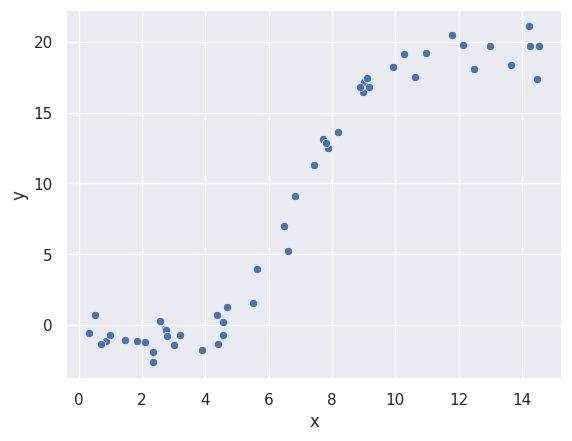

In [27]:
sns.scatterplot(df3, x='x', y='y');

In [28]:
lr3a = LinearRegression()
lr3a.fit(df3[['x']], df3['y'])
lr3a.score(df3[['x']], df3['y'])

0.8858908011607038

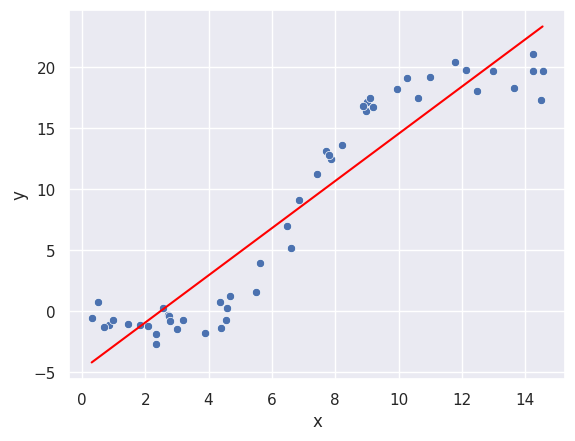

In [29]:
ypa = lr3a.coef_[0]*df3['x'] + lr3a.intercept_
sns.scatterplot(df3, x='x', y='y')
sns.lineplot(x=df3['x'], y=ypa, color='red');

## Generacja zmiennych (3 stopnia)

In [30]:
df3['x2'] = df3['x']**2
df3['x3'] = df3['x']**3
df3.info()
df3.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       50 non-null     float64
 1   y       50 non-null     float64
 2   x2      50 non-null     float64
 3   x3      50 non-null     float64
dtypes: float64(4)
memory usage: 1.7 KB


,x,y,x2,x3
0,5.618102,3.921815,31.563068,177.324527
1,14.260715,19.737921,203.367981,2900.172732
2,10.979909,19.235973,120.558404,1323.720325
3,8.979877,16.446945,80.638196,724.121100
4,2.340280,-2.646678,5.476909,12.817498


In [31]:
lr3b = LinearRegression()
lr3b.fit(df3[['x', 'x2']], df3['y'])
lr3b.score(df3[['x', 'x2']], df3['y'])

0.8895539225229137

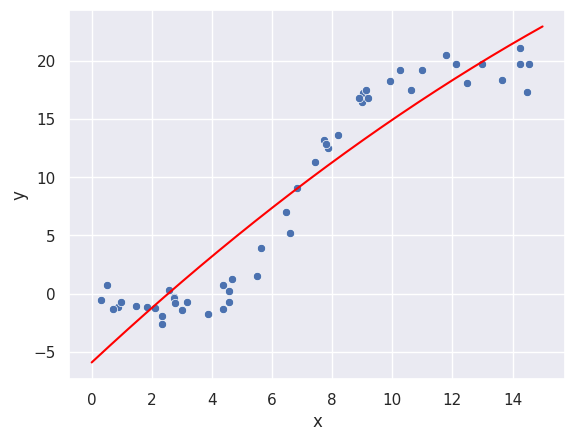

In [32]:
xfit = np.linspace(0, 15, 200)
yfit = lr3b.coef_[0]*xfit + lr3b.coef_[1]*xfit**2 + lr3b.intercept_
sns.scatterplot(df3, x='x', y='y')
sns.lineplot(x=xfit, y=yfit, color='red');

In [33]:
lr3c = LinearRegression()
lr3c.fit(df3[['x', 'x2', 'x3']], df3['y'])
lr3c.score(df3[['x', 'x2', 'x3']], df3['y'])

0.976469155967986

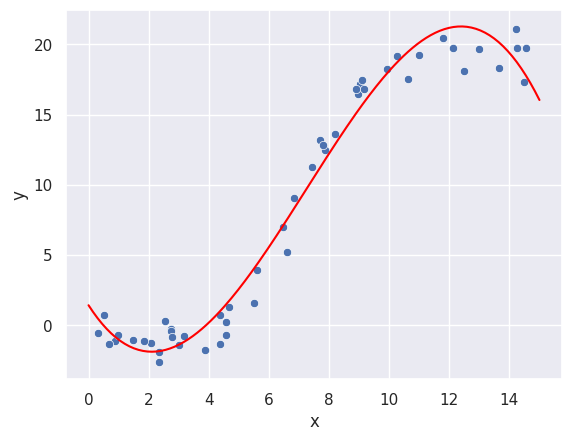

In [34]:
yfit = lr3c.coef_[0]*xfit + lr3c.coef_[1]*xfit**2 + lr3c.coef_[2]*xfit**3 + lr3c.intercept_
sns.scatterplot(df3, x='x', y='y')
sns.lineplot(x=xfit, y=yfit, color='red');

## Weryfikacja modeli na danych testowych

In [35]:
df_test = pd.read_csv('reglin_1_test.csv')
df_test.info()
df_test.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       20 non-null     float64
 1   y       20 non-null     float64
dtypes: float64(2)
memory usage: 452.0 bytes


,x,y
0,0.213221,-5.680260
1,7.021642,7.507839
2,7.912244,11.717567
3,8.649310,12.058167
4,3.696789,1.450632


In [36]:
print('R2 (train) =', lr.score(df[['x']], df['y']))
print('R2 (test)  =', lr.score(df_test[['x']], df_test['y']))

R2 (train) = 0.9749140085676858
R2 (test)  = 0.9511993417081333


In [37]:
df2_test = pd.read_csv('reglin_2_test.csv')
df2_test.info()
df2_test.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       20 non-null     float64
 1   y       20 non-null     float64
dtypes: float64(2)
memory usage: 452.0 bytes


,x,y
0,5.813768,6.360119
1,1.722501,-1.949663
2,4.007358,0.250559
3,7.809559,10.773168
4,6.317891,5.237792


In [38]:
df2_test['x2'] = df2_test['x']**2

In [39]:
print('R2 (train) =', lr2b.score(df2[['x', 'x2']], df2['y']))
print('R2 (test)  =', lr2b.score(df2_test[['x', 'x2']], df2_test['y']))

R2 (train) = 0.9626730764178592
R2 (test)  = 0.9617553001024589


In [52]:
df3_test = pd.read_csv('reglin_3_test.csv')
df3_test.info()
df3_test.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       20 non-null     float64
 1   y       20 non-null     float64
dtypes: float64(2)
memory usage: 452.0 bytes


,x,y
0,10.282111,18.767247
1,3.499363,-1.078100
2,13.657689,18.938002
3,12.595867,21.611610
4,9.491453,18.004304


In [41]:
df3_test['x2'] = df3_test['x']**2
df3_test['x3'] = df3_test['x']**3

In [42]:
print('R2 (train) =', lr3c.score(df3[['x', 'x2', 'x3']], df3['y']))
print('R2 (test)  =', lr3c.score(df3_test[['x', 'x2', 'x3']], df3_test['y']))

R2 (train) = 0.976469155967986
R2 (test)  = 0.9909421144951408


## Generowanie cech wielomianowych (scikit-learn)

In [43]:
from sklearn.preprocessing import PolynomialFeatures
sklearn.set_config(transform_output='pandas')

In [44]:
pf2 = PolynomialFeatures(2, include_bias=False)
#pf2 = PolynomialFeatures(2, include_bias=False).set_output(transform='pandas')
#df2_p = pd.DataFrame(pf2.fit_transform(df2[['x']]), columns=pf2.get_feature_names_out())
df2_p = pf2.fit_transform(df2[['x']])
df2_p.info()
df2_p.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       50 non-null     float64
 1   x^2     50 non-null     float64
dtypes: float64(2)
memory usage: 932.0 bytes


,x,x^2
0,3.745401,14.028030
1,9.507143,90.385769
2,7.319939,53.581513
3,5.986585,35.839198
4,1.560186,2.434182


### Dwie zmienne niezależne

In [45]:
df12a = pd.read_csv('reglin_12a.csv')
df12a.info()
df12a.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      50 non-null     float64
 1   x2      50 non-null     float64
 2   y       50 non-null     float64
dtypes: float64(3)
memory usage: 1.3 KB


,x1,x2,y
0,3.745401,6.787092,19.711922
1,9.507143,5.425930,-3.545824
2,7.319939,6.576493,13.649960
3,5.986585,6.263791,13.781466
4,1.560186,4.185300,7.478136


In [46]:
fig = go.Figure()
fig.add_scatter3d(x=df12a['x1'], y=df12a['x2'], z=df12a['y'],
                  mode='markers', marker=dict(color='blue'))
fig.update_layout(scene = dict(xaxis=dict(title=dict(text='x1')),
                               yaxis=dict(title=dict(text='x2')),
                               zaxis=dict(title=dict(text='y'))))
fig.show()

In [47]:
lr12a = LinearRegression()
lr12a.fit(df12a[['x1', 'x2']], df12a['y'])
yp12a = lr12a.predict(df12a[['x1', 'x2']])
print('a =  ', lr12a.coef_)
print('b = ', lr12a.intercept_)
print('R2 =', lr12a.score(df12a[['x1', 'x2']], df12a['y']))

a =   [-2.06747213  3.49311209]
b =  -0.17381491318514453
R2 = 0.8510852860212862


In [48]:
pf12 = PolynomialFeatures(2, include_bias=False)
df12_p = pf12.fit_transform(df12a[['x1', 'x2']])
df12_p.info()
df12_p.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50 entries, 0 to 49
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x1      50 non-null     float64
 1   x2      50 non-null     float64
 2   x1^2    50 non-null     float64
 3   x1 x2   50 non-null     float64
 4   x2^2    50 non-null     float64
dtypes: float64(5)
memory usage: 2.1 KB


,x1,x2,x1^2,x1 x2,x2^2
0,3.745401,6.787092,14.028030,25.420384,46.064623
1,9.507143,5.425930,90.385769,51.585091,29.440714
2,7.319939,6.576493,53.581513,48.139527,43.250255
3,5.986585,6.263791,35.839198,37.498719,39.235083
4,1.560186,4.185300,2.434182,6.529848,17.516735


In [49]:
lr12b = LinearRegression()
lr12b.fit(df12_p, df12a['y'])
yp12b = lr12b.predict(df12_p)
print('a =  ', lr12b.coef_)
print('b = ', lr12b.intercept_)
print('R2 =', lr12b.score(df12_p, df12a['y']))

a =   [ 0.86687365 -1.06918218 -0.36497607  0.20318755  0.49916902]
b =  1.3248913003097202
R2 = 0.9917422632363089


In [50]:
x1_fit = np.linspace(0, 10, 100)
x2_fit = np.linspace(0, 7, 100)
X1, X2 = np.meshgrid(x1_fit, x2_fit)
Y = lr12b.coef_[0]*X1 + lr12b.coef_[1]*X2 + lr12b.coef_[2]*X1**2 + lr12b.coef_[3]*X1*X2 + lr12b.coef_[4]*X2**2 + lr12b.intercept_

In [51]:
fig = go.Figure(data=[go.Surface(x=X1, y=X2, z=Y,
                                 colorscale=[[0, 'red'], [1, 'red']],
                                 showscale=False,
                                 opacity=0.6)])
fig.add_scatter3d(x=df12a['x1'], y=df12a['x2'], z=df12a['y'],
                  mode='markers', marker=dict(color='blue'))
fig.update_layout(scene = dict(xaxis=dict(title=dict(text='x1')),
                               yaxis=dict(title=dict(text='x2')),
                               zaxis=dict(title=dict(text='y'))))
fig.show()